 # Notebook 06 — LWC Retrieval Uncertainty (Zhu et al. 2019, Eq. 5–8)



 This notebook attaches a **1-sigma uncertainty to every retrieved LWC value**.



 Why this matters: "37 % of my LWC values are negative" is a weak statement,

 because a value of -0.05 g/m3 with an uncertainty of 0.34 g/m3 is perfectly

 consistent with zero. Socuellamos et al. (2024) make exactly this argument:

 they keep their negative values and show that ">95 % of the negative numbers

 can become positive within the uncertainty limits". Once we have sigma_LWC we

 can replace "fraction negative" with "fraction SIGNIFICANTLY negative", which

 is a much more defensible number.



 ## The equations we implement



 Zhu Eq. (6) — random error of one reflectivity measurement, in dB:



     dZ_f = 4.343 / sqrt(dt * PRF_f * N)

            * [ lambda_f * PRF_f / (4*sqrt(pi)*sigma_w_f) + 1/SNR_f^2 + 2/SNR_f ]^(1/2)



 Zhu Eq. (5) — LWC uncertainty of ONE retrieval window:



     dq_L = sqrt(dZ_f1^2 + dZ_f2^2) / [ sqrt(2) * (kappa_f1 - kappa_f2) * dh ]



 Zhu Eq. (7) — reduction from averaging M overlapping windows:



     dq_L_final = dq_L / sqrt(M_eff)



 Zhu Eq. (8) — effective sample size, accounting for window overlap:



     M_eff = M / (1 + 2 * sum_k rho(k))



 ## IMPORTANT: a labelling error in the Zhu paper



 Zhu's text describes `dh` in Eq. (5) as "the range gate spacing (in m)".

 **That is wrong.** Hogan et al. (2005), whose equations Zhu is reproducing,

 uses `(h2 - h1)` — the separation between the two heights spanning the DWR

 gradient — and Hogan Eq. (7) states explicitly:

 *"recognising that h2 - h1 = N*delta (where delta is the range gate spacing)"*.



 Combining Zhu (5)+(6) reproduces Hogan (7) **only** if dh = N * gate_spacing.

 Checked numerically: using the gate spacing instead of the window span

 overestimates the uncertainty by exactly a factor of N.



 So in this notebook `dh` is always the **vertical span of the fitting window**

 = N_gates_in_window * gate_spacing.



 ## A caveat about the theoretical route



 Hogan's Appendix states his Eq. (6) assumes *"the radar is ... of the ordinary

 pulsed type, utilizing a square-law detector and performing linear averages

 with no spectral processing"*. Our radar is an **RPG FMCW** system, which is

 none of those things. The theoretical dZ is therefore best read as a

 **lower bound** on the true noise — what the noise would be if only receiver

 noise mattered. The gap between it and the measured noise tells us how much

 other error (range sidelobes, beam mismatch, clutter) is present.

 ---

 ## Step 0 — Imports and loading

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

sys.path.append(str(Path("../src").resolve()))


In [2]:
Processed_Dataset = "20261001_pallas_interpolation"

In [3]:
# The base retrieval inputs, written by notebook 03.
# Contains: Ze_W, Ze_Ka, T_cloud, LWP, DWR, cloud_mask, combined_mask,
#           common_mask, alpha_W, alpha_Ka, kappa_W, kappa_Ka,
#           MeanVel_W, MeanVel_Ka
path_retrieval_input = Path(f"../data/processed/{Processed_Dataset}/retrieval_input_4km_alpha_kappa_calculated.nc")
ds_retrieval = xr.open_dataset(path_retrieval_input)

# The retrieval OUTPUTS, written by the new export cells in notebooks 04 and 05.
# Contains: lwc_guarded, n_windows, dwr_filtered   (from 04)
#           lwc_dq, dq                             (from 05)
path_zhu_output = Path(f"../data/processed/{Processed_Dataset}/retrieval_output_zhu.nc")
path_dq_output = Path(f"../data/processed/{Processed_Dataset}/retrieval_output_dq.nc")

ds_zhu = xr.open_dataset(path_zhu_output)
ds_dq = xr.open_dataset(path_dq_output)

print("Zhu output variables:", list(ds_zhu.data_vars))
print("DQ  output variables:", list(ds_dq.data_vars))


Zhu output variables: ['lwc_guarded', 'n_windows', 'dwr_filtered', 'm_eff', 'derivative_guarded', 'n_used']
DQ  output variables: ['lwc_dq', 'dq']


In [4]:
# Pull out the pieces we will use repeatedly, with explicit names.
# `.values` converts an xarray DataArray into a plain NumPy array. We do this
# where we want fast arithmetic and do not need the coordinate labels.

mask_retrieval = ds_retrieval["common_mask"]          # True = gate used in retrieval
dwr_filtered = ds_zhu["dwr_filtered"]                 # 30 s averaged + despiked DWR
lwc_zhu = ds_zhu["lwc_guarded"]                       # LWC from the Zhu retrieval
n_windows_zhu = ds_zhu["n_windows"]                   # how many windows hit each gate
lwc_dq = ds_dq["lwc_dq"]                              # LWC from the DQ retrieval

kappa_W = ds_retrieval["kappa_W"]
kappa_Ka = ds_retrieval["kappa_Ka"]

# Gate spacing in kilometres.
# `.diff("range")` gives the difference between consecutive range values.
# We take the mean because the spacing can vary slightly between chirps.
TR      = lambda a: a.transpose("Time", "range")
target  = TR(dwr_filtered)
to_grid = lambda a: TR(a).reindex_like(target)


r = target["range"].values.astype(float)      # the grid the retrieval ran on
sp = np.round(np.diff(r), 1)

vals, counts = np.unique(sp, return_counts=True)
print(f"grid: {r[0]:.0f}-{r[-1]:.0f} m, {len(r)} gates")
for v, c in zip(vals, counts):
    print(f"  spacing {v:5.1f} m : {c:3d} intervals")

gate_spacing_m = float(vals[np.argmax(counts)])   # the mode, not the mean/median
gate_spacing_km = gate_spacing_m / 1000.0
uniform = len(vals) == 1

print(f"\ngate spacing = {gate_spacing_m:.1f} m"
      f"{'' if uniform else '   <-- GRID NOT UNIFORM'}")


grid: 224-3986 m, 229 gates
  spacing   9.0 m :   1 intervals
  spacing  13.5 m : 133 intervals
  spacing  14.9 m :  65 intervals
  spacing  34.1 m :  28 intervals
  spacing  35.2 m :   1 intervals

gate spacing = 13.5 m   <-- GRID NOT UNIFORM


 ---

 ## Step 1 — Radar parameters



 **Everything in this cell is an assumption.** They are collected in one place

 so they are easy to find, easy to change, and easy to list in the thesis as

 stated assumptions. Replace them with real values as you obtain them.

In [5]:
SPEED_OF_LIGHT_M_PER_S = 2.99792458e8

frequency_W_hz = 94.0e9
frequency_Ka_hz = 35.0e9

wavelength_W_m = SPEED_OF_LIGHT_M_PER_S / frequency_W_hz     # 3.189 mm
wavelength_Ka_m = SPEED_OF_LIGHT_M_PER_S / frequency_Ka_hz   # 8.565 mm

# --- ASSUMPTION 1: pulse repetition frequency -------------------------------
# Taken from Hogan et al. (2005), who use 6250 Hz at both frequencies in their
# worked example. NOTE: an FMCW radar does not really have a PRF; the
# equivalent quantity is the chirp repetition rate, which differs per chirp.
# This is a placeholder. Ask RPG or read it from the LV1 file header.
prf_W_hz = 6250.0
prf_Ka_hz = 6250.0

# --- ASSUMPTION 2: Doppler spectral width -----------------------------------
# Hogan uses 0.3 m/s for stratocumulus. If your LV1 files contain a spectral
# width variable (often C1SpecWidth etc.), load it and use the real values.
spectral_width_W_m_per_s = 0.3
spectral_width_Ka_m_per_s = 0.3

# --- ASSUMPTION 3: signal-to-noise ratio ------------------------------------
# Given as a LINEAR ratio, not dB.  linear = 10 ** (dB / 10)
# 20 dB is a reasonably good in-cloud value. Section 1b below shows how to
# compute the real SNR per gate from the sensitivity limits instead.
snr_W_linear = 10 ** (20.0 / 10.0)
snr_Ka_linear = 10 ** (20.0 / 10.0)

# --- ASSUMPTION 4: dwell time -----------------------------------------------
# This is the temporal averaging applied before the retrieval.
dwell_time_s = 30.0

# --- Retrieval window -------------------------------------------------------
# N_default in retrieve_lwc_zhu_guarded. This is what sets `dh`.
n_used = ds_zhu["n_used"] 
n_gates_in_window = ds_zhu["n_used"]   # The Same? Need to check if this is correct. Need it in step 3
window_span_km = n_used * gate_spacing_km     # (Time,), broadcasts over range

valid = n_used > 0
print(f"lambda_W  = {wavelength_W_m * 1000:.3f} mm")
print(f"lambda_Ka = {wavelength_Ka_m * 1000:.3f} mm")
print(f"N used: median {float(n_used.where(valid).median()):.0f}, "
      f"min {int(n_used.where(valid).min())}, "
      f"max {int(n_used.max())} gates")
print(f"Window span dh: median "
      f"{float(window_span_km.where(valid).median()) * 1000:.0f} m, "
      f"range {float(window_span_km.where(valid).min()) * 1000:.0f}-"
      f"{float(window_span_km.max()) * 1000:.0f} m")
print(f"  (previously assumed {9 * gate_spacing_m:.0f} m for every profile)")
print(f"  (NOT the gate spacing of {gate_spacing_m:.1f} m -- see the note above)")

lambda_W  = 3.189 mm
lambda_Ka = 8.565 mm
N used: median 9, min 3, max 9 gates
Window span dh: median 122 m, range 40-122 m
  (previously assumed 122 m for every profile)
  (NOT the gate spacing of 13.5 m -- see the note above)


 ### Step 1b — (optional) real SNR from the sensitivity limits



 If your dataset carries `SLv_W` / `SLv_Ka`, you can compute a real per-gate

 SNR instead of assuming a constant. SNR in dB is simply signal minus noise

 floor when both are in dB:



     SNR_dB = Ze_dBZ - SL_dBZ



 Caveat: this assumes the sensitivity-limit field is calibrated as the

 noise-equivalent reflectivity. That is standard practice but is still

 unconfirmed for this instrument, so treat the result as provisional.

In [6]:
if "SLv_W" in ds_retrieval and "SLv_Ka" in ds_retrieval:
    # 10*log10 converts the linear mm^6/m^3 sensitivity limit into dBZ
    sensitivity_limit_W_dbz = 10.0 * np.log10(ds_retrieval["SLv_W"])
    sensitivity_limit_Ka_dbz = 10.0 * np.log10(ds_retrieval["SLv_Ka"])

    snr_W_db_field = (ds_retrieval["Ze_W"] - sensitivity_limit_W_dbz).where(mask_retrieval)
    snr_Ka_db_field = (ds_retrieval["Ze_Ka"] - sensitivity_limit_Ka_dbz).where(mask_retrieval)

    # np.nanmedian ignores NaNs. The median is more robust than the mean here
    # because a few very low-SNR gates would drag a mean down a lot.
    snr_W_db_median = float(np.nanmedian(snr_W_db_field.values))
    snr_Ka_db_median = float(np.nanmedian(snr_Ka_db_field.values))

    print(f"Median in-cloud SNR, W-band : {snr_W_db_median:5.1f} dB")
    print(f"Median in-cloud SNR, Ka-band: {snr_Ka_db_median:5.1f} dB")
    print("\nTo use these instead of the assumed 20 dB, uncomment the two lines below.")
     #snr_W_linear  = 10 ** (snr_W_db_median / 10.0)
     #snr_Ka_linear = 10 ** (snr_Ka_db_median / 10.0)
else:
    print("SLv_W / SLv_Ka not in the dataset - keeping the assumed SNR of 20 dB.")
    print("Add them to the notebook 03 export if you want the real values.")


SLv_W / SLv_Ka not in the dataset - keeping the assumed SNR of 20 dB.
Add them to the notebook 03 export if you want the real values.


 ---

 ## Step 2 — The EMPIRICAL route: measure the DWR noise from the data



 Before trusting any model, measure the noise that is actually there.



 **Derivation.** Write the measured DWR at gate *i* as

 `D_i = d_i + eps_i`, where `d_i` is the true DWR and `eps_i` is random error

 with variance `sigma^2`. The gate-to-gate difference is



     Delta_i = D_(i+1) - D_i = (d_(i+1) - d_i) + (eps_(i+1) - eps_i)



 **Assumption:** the true DWR barely changes between adjacent gates, so

 `d_(i+1) ≈ d_i`. Then, because the two errors are independent

 (so their covariance is zero):



     Var(Delta) = Var(eps_(i+1)) + Var(eps_i) = 2 * sigma^2



 and therefore `sigma = std(Delta) / sqrt(2)`.

In [7]:
# Take the DWR only where the retrieval mask is True; everything else is NaN.
dwr_masked_values = dwr_filtered.where(mask_retrieval).values

# Difference between consecutive range gates.
# dwr_masked_values[:, 1:]  -> all times, gates 1..end
# dwr_masked_values[:, :-1] -> all times, gates 0..end-1
# Subtracting them gives DWR(i+1) - DWR(i) for every gate pair.
dwr_gate_differences = dwr_masked_values[:, 1:] - dwr_masked_values[:, :-1]

# np.isfinite is True for real numbers and False for NaN or infinity.
# Using it as an index keeps only the valid entries and flattens the array.
dwr_gate_differences = dwr_gate_differences[np.isfinite(dwr_gate_differences)]

sigma_dwr_per_gate_db = float(np.std(dwr_gate_differences) / np.sqrt(2.0))

# reduce by sqrt(N), same N as Zhu Eq. 6, so measured and theoretical match
sigma_dwr_measured_db = sigma_dwr_per_gate_db / np.sqrt(n_used.where(valid))

sigma_dwr_measured_median = float(sigma_dwr_measured_db.median())    # Meadian to make comparison easier with the theoretical random error from equation 6 of Zhu.
# sigma_dwr_measured_db    = sigma_dwr_measured_db / np.sqrt(n_used)   # I changed to window with n_used instead of just the gate difference because the theoretical random error from equation 6 of Zhu also takes the number of independent samples N into account for the whole window and I need to compare to that right?


print(f"Valid gate pairs used         : {dwr_gate_differences.size}")
print(f"std of gate-to-gate difference: {np.std(dwr_gate_differences):.3f} dB")
print(f"per-gate DWR noise            : {sigma_dwr_per_gate_db:.3f} dB")
print(f"after /sqrt(N), median        : {sigma_dwr_measured_median:.3f} dB")


Valid gate pairs used         : 177144
std of gate-to-gate difference: 1.831 dB
per-gate DWR noise            : 1.295 dB
after /sqrt(N), median        : 0.432 dB


In [8]:
# How much of that std is real signal rather than noise?
# A true DWR gradient of ~5 dB/km over one gate contributes:
assumed_true_gradient_db_per_km = 5.0
signal_per_gate_db = assumed_true_gradient_db_per_km * gate_spacing_km


print(f"A {assumed_true_gradient_db_per_km:.0f} dB/km gradient contributes "
      f"{signal_per_gate_db:.3f} dB per gate,")



A 5 dB/km gradient contributes 0.068 dB per gate,


 ---

 ## Step 3 — The THEORETICAL route: Zhu Eq. (6)



 `4.343` is the conversion factor from natural logarithm units (nepers) to

 decibels: `10 / ln(10) = 4.3429`.

In [9]:
def reflectivity_error_db(wavelength_m, prf_hz, spectral_width_m_per_s,
                          snr_linear, dwell_time_s, n_gates):
    """
    Zhu et al. (2019) Eq. (6) / Hogan et al. (2005) Eq. (6).

    Random error of an averaged reflectivity measurement, in dB.

    Parameters
    ----------
    wavelength_m           : radar wavelength [m]
    prf_hz                 : pulse repetition frequency [Hz]
    spectral_width_m_per_s : Doppler spectral width [m/s]
    snr_linear             : signal-to-noise ratio, LINEAR (not dB)
    dwell_time_s           : temporal averaging applied [s]
    n_gates                : number of range gates grouped together

    Returns
    -------
    Random reflectivity error [dB]
    """
    # Number of independent samples averaged in time.
    n_independent_time_samples = dwell_time_s * prf_hz

    # The three terms inside the square-root bracket of Eq. (6).
    # Term 1 is the finite-bandwidth / spectral-broadening term.
    # Terms 2 and 3 are the SNR-dependent noise terms. They vanish when SNR is
    # large, which is why high SNR matters.
    term_spectral = (wavelength_m * prf_hz
                     / (4.0 * np.sqrt(np.pi) * spectral_width_m_per_s))
    term_snr_squared = 1.0 / snr_linear ** 2
    term_snr_linear = 2.0 / snr_linear

    bracket = term_spectral + term_snr_squared + term_snr_linear

    return (4.343 / np.sqrt(n_independent_time_samples * n_gates)
            * np.sqrt(bracket))


reflectivity_error_W_db = reflectivity_error_db(
    wavelength_W_m, prf_W_hz, spectral_width_W_m_per_s,
    snr_W_linear, dwell_time_s, n_used)

reflectivity_error_Ka_db = reflectivity_error_db(
    wavelength_Ka_m, prf_Ka_hz, spectral_width_Ka_m_per_s,
    snr_Ka_linear, dwell_time_s, n_used)

# The DWR is a difference of two independent reflectivities, so its error is
# the root-sum-square of the two individual errors.
sigma_dwr_theoretical_db = np.sqrt(
    reflectivity_error_W_db ** 2 + reflectivity_error_Ka_db ** 2)

sigma_dwr_theoretical_median = float(sigma_dwr_theoretical_db.where(valid).median())

print(f"dZ_W  (Zhu Eq. 6) median = "
      f"{float(reflectivity_error_W_db.where(valid).median()):.4f} dB")
print(f"dZ_Ka (Zhu Eq. 6) median = "
      f"{float(reflectivity_error_Ka_db.where(valid).median()):.4f} dB")
print(f"=> theoretical DWR noise (median) = {sigma_dwr_theoretical_median:.4f} dB")
print(f"=> theoretical DWR noise (median) = {sigma_dwr_theoretical_median:.4f} dB")


dZ_W  (Zhu Eq. 6) median = 0.0102 dB
dZ_Ka (Zhu Eq. 6) median = 0.0168 dB
=> theoretical DWR noise (median) = 0.0197 dB
=> theoretical DWR noise (median) = 0.0197 dB


 ---

 ## Step 4 — Compare the two routes



 This comparison is itself a result. If the measured noise is far larger than

 the receiver-noise model predicts, then receiver noise is **not** what limits

 the retrieval, and pushing SNR higher will not help much.

In [10]:
ratio_field = sigma_dwr_measured_db / sigma_dwr_theoretical_db
ratio_measured_to_theoretical = float(ratio_field.where(valid).median())

print(f"measured    sigma_DWR = {sigma_dwr_measured_median:.3f} dB")
print(f"theoretical sigma_DWR = {sigma_dwr_theoretical_median:.3f} dB")
print(f"ratio                 = {ratio_measured_to_theoretical:.1f}x")
print()
if ratio_measured_to_theoretical > 3:
    print("The measured noise greatly exceeds the receiver-noise model.")
    print("Receiver noise is NOT the limiting factor. Likely contributors:")
    print("  - range sidelobe leakage (FMCW / pulse compression; Hogan 2005")
    print("    warns this technique needs ~0.03 dB precision and that FMCW")
    print("    radars are unlikely to achieve it)")
    print("  - beam / sampling-volume mismatch between two separate radars")
    print("    (Zhu could neglect this because the SACR2 is a single instrument)")
    print("  - residual clutter or drizzle inside the mask")
    print()
    print("Hogan's stated precision requirement for this technique: ~0.03 dB")
    print(f"Ours: {sigma_dwr_measured_median:.2f} dB "
          f"({sigma_dwr_measured_median / 0.03:.0f}x larger)")


measured    sigma_DWR = 0.432 dB
theoretical sigma_DWR = 0.020 dB
ratio                 = 22.0x

The measured noise greatly exceeds the receiver-noise model.
Receiver noise is NOT the limiting factor. Likely contributors:
  - range sidelobe leakage (FMCW / pulse compression; Hogan 2005
    warns this technique needs ~0.03 dB precision and that FMCW
    radars are unlikely to achieve it)
  - beam / sampling-volume mismatch between two separate radars
    (Zhu could neglect this because the SACR2 is a single instrument)
  - residual clutter or drizzle inside the mask

Hogan's stated precision requirement for this technique: ~0.03 dB
Ours: 0.43 dB (14x larger)


 ---

 ## Step 5 — Zhu Eq. (5): uncertainty of a single retrieval window



     dq_L = sqrt(dZ_f1^2 + dZ_f2^2) / [ sqrt(2) * (kappa_f1 - kappa_f2) * dh ]



 Where does the `sqrt(2)` come from? LWC is derived from a *difference* of two

 DWR values, and the error of a difference of two independent quantities is

 `sqrt(2)` times the individual error. Combined with the factor 2 that

 accounts for two-way attenuation, `sqrt(2)*dDWR / (2*dkappa*dh)` simplifies to

 `dDWR / (sqrt(2)*dkappa*dh)`.

In [11]:
def lwc_uncertainty_single_window(sigma_dwr_db, delta_kappa, window_span_km):
    """
    Zhu Eq. (5). Uncertainty of one LWC retrieval window.

    sigma_dwr_db   : DWR error [dB]  (= sqrt(dZ_f1^2 + dZ_f2^2))
    delta_kappa    : kappa_W - kappa_Ka  [dB / km / (g/m3)]
    window_span_km : N_gates * gate_spacing, in km   <-- NOT the gate spacing
    """
    return sigma_dwr_db / (np.sqrt(2.0) * delta_kappa * window_span_km)


# delta_kappa is a full 2-D field because kappa depends on temperature.
delta_kappa_field = kappa_W - kappa_Ka

print(f"delta_kappa: min {float(delta_kappa_field.min()):.2f}, "
      f"median {float(delta_kappa_field.median()):.2f}, "
      f"max {float(delta_kappa_field.max()):.2f} dB/km/(g/m3)")

lwc_uncertainty_single_measured = lwc_uncertainty_single_window(
    sigma_dwr_measured_db, delta_kappa_field, window_span_km)

lwc_uncertainty_single_theoretical = lwc_uncertainty_single_window(
    sigma_dwr_theoretical_db, delta_kappa_field, window_span_km)

print(f"\nSingle-window LWC uncertainty (median over the cloud):")
print(f"  from measured noise    : "
      f"{float(lwc_uncertainty_single_measured.where(mask_retrieval).median()):.3f} g/m3")
print(f"  from theoretical noise : "
      f"{float(lwc_uncertainty_single_theoretical.where(mask_retrieval).median()):.3f} g/m3")
print(f"\nZhu reported 0.10-0.65 g/m3 for their clouds.")


delta_kappa: min 3.47, median 3.62, max 3.70 dB/km/(g/m3)

Single-window LWC uncertainty (median over the cloud):
  from measured noise    : 0.699 g/m3
  from theoretical noise : 0.032 g/m3

Zhu reported 0.10-0.65 g/m3 for their clouds.


 ### Sanity check: what happens with the WRONG dh?



 Demonstrating the factor-N error, so it is documented rather than assumed.

In [12]:

lwc_uncertainty_wrong_dh = lwc_uncertainty_single_window(
    sigma_dwr_measured_db, delta_kappa_field, gate_spacing_km)

valid = n_used > 0
median_correct = float(lwc_uncertainty_single_measured.where(mask_retrieval).median())
median_wrong   = float(lwc_uncertainty_wrong_dh.where(mask_retrieval).median())
median_span_m  = float(window_span_km.where(valid).median()) * 1000.0
median_N       = float(n_used.where(valid).median())

print(f"dh = window span (median {median_span_m:.0f} m) -> "
      f"{median_correct:.3f} g/m3   [CORRECT]")
print(f"dh = gate spacing ({gate_spacing_m:.0f} m)        -> "
      f"{median_wrong:.3f} g/m3   [WRONG]")
print(f"ratio = {median_wrong / median_correct:.1f}   "
      f"(median N = {median_N:.0f})")


dh = window span (median 122 m) -> 0.699 g/m3   [CORRECT]
dh = gate spacing (14 m)        -> 6.295 g/m3   [WRONG]
ratio = 9.0   (median N = 9)


 ---

 ## Step 6 — Zhu Eq. (7) and (8): averaging over overlapping windows





In [13]:

# Load the empirically-computed M_eff (Zhu Eq. 8), exported from zhu.py via notebook 04
m_effective = ds_zhu["m_eff"]

print(f"M_eff per gate: median {float(m_effective.median()):.2f}, "
      f"p05 {float(m_effective.quantile(0.05)):.2f}, "
      f"p95 {float(m_effective.quantile(0.95)):.2f}, "
      f"max {float(m_effective.max()):.2f}")
print(f"windows per gate M: median {float(ds_zhu['n_windows'].where(ds_zhu['n_windows']>0).median()):.1f}, "
      f"max {float(ds_zhu['n_windows'].max()):.0f}")
print(f"resulting reduction factor: median {np.sqrt(float(m_effective.median())):.2f}")

lwc_uncertainty_final = (lwc_uncertainty_single_measured
                         / np.sqrt(m_effective)).where(mask_retrieval)
lwc_uncertainty_final.name = "LWC_uncertainty"
lwc_uncertainty_final.attrs = {
    "units": "g m-3",
    "long_name": "1-sigma LWC retrieval uncertainty",
    "method": "Zhu et al. (2019) Eq. 5-8, sigma_DWR measured from data",
    "note": "dh = N * gate spacing (window span), NOT the gate spacing",
    "sigma_dwr_db": sigma_dwr_measured_median,
}

print(f"Final per-gate LWC uncertainty:")
print(f"  median {float(lwc_uncertainty_final.median()):.3f} g/m3")
print(f"  p05    {float(lwc_uncertainty_final.quantile(0.05)):.3f} g/m3")
print(f"  p95    {float(lwc_uncertainty_final.quantile(0.95)):.3f} g/m3")


M_eff per gate: median 2.00, p05 1.00, p95 4.00, max 9.00
windows per gate M: median 3.0, max 9
resulting reduction factor: median 1.41
Final per-gate LWC uncertainty:
  median 0.497 g/m3
  p05    0.349 g/m3
  p95    0.702 g/m3


 ---

 ## Step 7 — The key result: how many negatives are SIGNIFICANTLY negative?



 This is the Socuellamos framing. A value is only meaningfully negative if it

 lies more than one sigma below zero, i.e. `LWC + sigma_LWC < 0`.

In [14]:
def significance_report(lwc_field, uncertainty_field, mask, label):
    """Compare the raw negative fraction with the significant negative fraction."""
    lwc_values = lwc_field.where(mask).values
    sigma_values = uncertainty_field.where(mask).values

    valid = np.isfinite(lwc_values) & np.isfinite(sigma_values)
    lwc_valid = lwc_values[valid]
    sigma_valid = sigma_values[valid]

    fraction_negative = (lwc_valid < 0).mean()
    # "significantly negative" = more than 1 sigma below zero
    fraction_significantly_negative = ((lwc_valid + sigma_valid) < 0).mean()
    # of the negatives, how many could be positive within 1 sigma?
    negatives = lwc_valid < 0
    if negatives.sum() > 0:
        fraction_rescued = ((lwc_valid[negatives] + sigma_valid[negatives]) >= 0).mean()
    else:
        fraction_rescued = np.nan

    print(f"--- {label} ---")
    print(f"  n valid gates                       : {lwc_valid.size}")
    print(f"  fraction LWC < 0                    : {fraction_negative:.1%}")
    print(f"  fraction significantly < 0 (>1 sigma): {fraction_significantly_negative:.1%}")
    print(f"  of the negatives, consistent with 0 : {fraction_rescued:.1%}")
    print(f"  (Socuellamos found >95% consistent with zero)")
    print()
    return fraction_negative, fraction_significantly_negative, fraction_rescued


results_zhu = significance_report(lwc_zhu, lwc_uncertainty_final,
                                  mask_retrieval, "Zhu guarded retrieval")
results_dq = significance_report(lwc_dq, lwc_uncertainty_final,
                                 mask_retrieval, "DQ integral retrieval")


--- Zhu guarded retrieval ---
  n valid gates                       : 125911
  fraction LWC < 0                    : 24.7%
  fraction significantly < 0 (>1 sigma): 13.3%
  of the negatives, consistent with 0 : 46.1%
  (Socuellamos found >95% consistent with zero)

--- DQ integral retrieval ---
  n valid gates                       : 125412
  fraction LWC < 0                    : 46.5%
  fraction significantly < 0 (>1 sigma): 38.7%
  of the negatives, consistent with 0 : 16.8%
  (Socuellamos found >95% consistent with zero)



 ---

 ## Step 8 — Plots

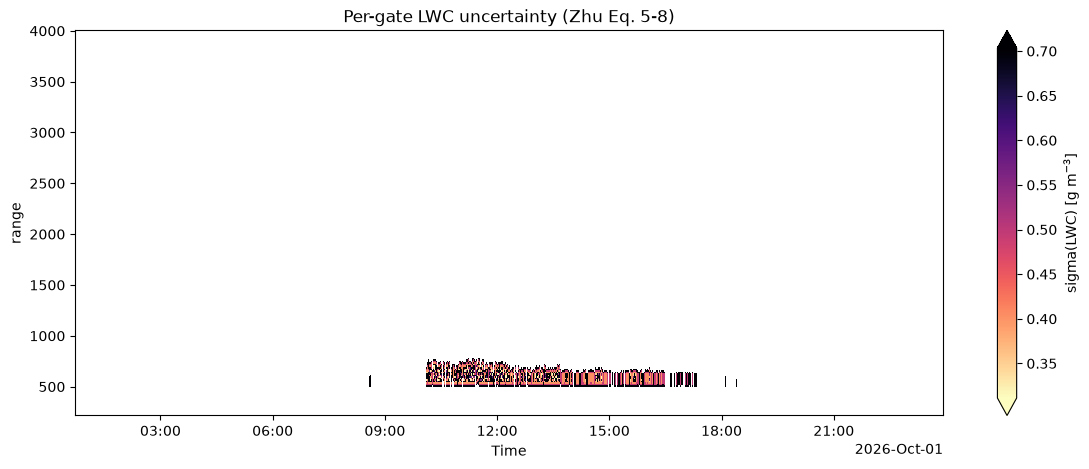

In [15]:
# 8a. The uncertainty field itself
fig, ax = plt.subplots(figsize=(14, 5))
lwc_uncertainty_final.plot(
    x="Time", y="range", ax=ax, cmap="magma_r", robust=True,
    cbar_kwargs={"label": "sigma(LWC) [g m$^{-3}$]"})
ax.set_title("Per-gate LWC uncertainty (Zhu Eq. 5-8)")
plt.show()


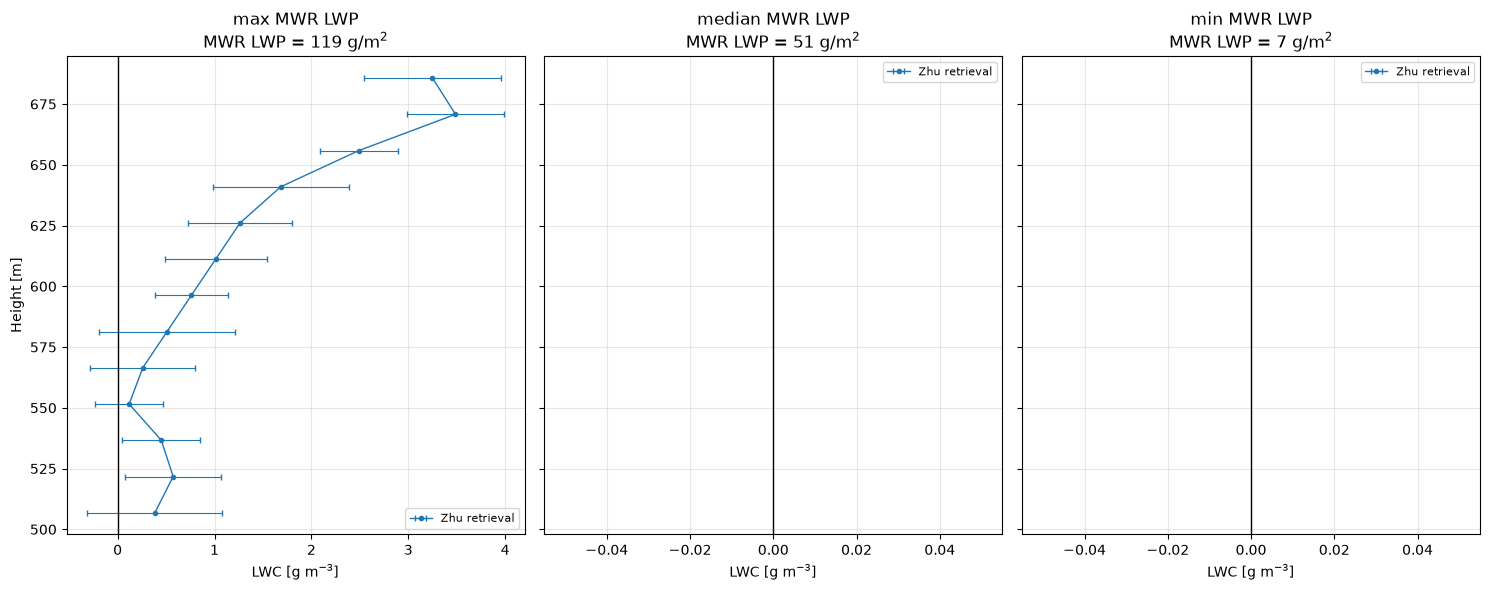

In [16]:
# 8b. LWC with error bars, for three example profiles.
# We pick the profile with the largest MWR LWP, one near the median, and one
# near the minimum, so we see a range of conditions.
lwp_mwr_values = ds_retrieval["LWP"].values
range_values_m = r 
# np.nanargmax returns the INDEX of the largest value, ignoring NaNs.
index_high_lwp = int(np.nanargmax(lwp_mwr_values))
index_median_lwp = int(np.nanargmin(np.abs(lwp_mwr_values - np.nanmedian(lwp_mwr_values))))
index_low_lwp = int(np.nanargmin(lwp_mwr_values))

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)

for ax, time_index, label in zip(
        axes,
        [index_high_lwp, index_median_lwp, index_low_lwp],
        ["max MWR LWP", "median MWR LWP", "min MWR LWP"]):

    lwc_profile = lwc_zhu.isel(Time=time_index).where(mask_retrieval.isel(Time=time_index))
    sigma_profile = lwc_uncertainty_final.isel(Time=time_index)

    ax.errorbar(
        lwc_profile.values, range_values_m,
        xerr=sigma_profile.values,
        fmt="o-", ms=3, lw=1, capsize=2, elinewidth=0.8,
        label="Zhu retrieval",
    )
    ax.axvline(0, color="k", lw=1.0)
    ax.set_xlabel("LWC [g m$^{-3}$]")
    ax.set_title(f"{label}\nMWR LWP = {lwp_mwr_values[time_index]:.0f} g/m$^2$")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Height [m]")
plt.tight_layout()
plt.show()


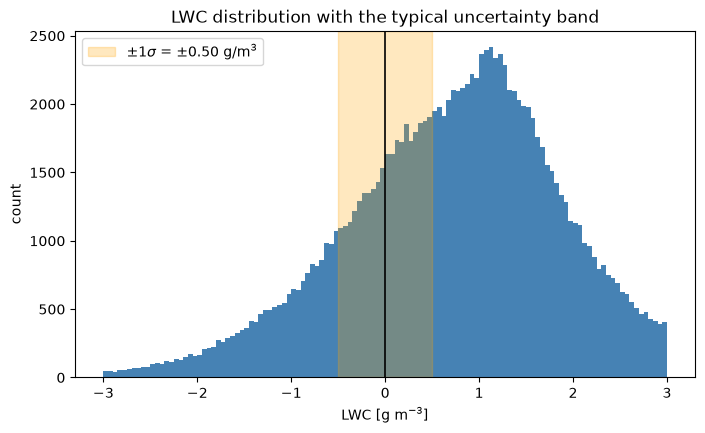

Fraction of all LWC values falling inside the +/-1 sigma band around zero: 24.2%
These values are statistically indistinguishable from zero.


In [17]:
# 8c. Histogram of LWC with the uncertainty band marked
lwc_values_flat = lwc_zhu.where(mask_retrieval).values
lwc_values_flat = lwc_values_flat[np.isfinite(lwc_values_flat)]
median_sigma = float(lwc_uncertainty_final.median())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(lwc_values_flat, bins=120, range=(-3, 3), color="steelblue")
ax.axvline(0, color="k", lw=1.2)
# axvspan shades a vertical band between two x values
ax.axvspan(-median_sigma, median_sigma, color="orange", alpha=0.25,
           label=f"$\\pm 1\\sigma$ = $\\pm${median_sigma:.2f} g/m$^3$")
ax.set_xlabel("LWC [g m$^{-3}$]")
ax.set_ylabel("count")
ax.set_title("LWC distribution with the typical uncertainty band")
ax.legend()
plt.show()

print(f"Fraction of all LWC values falling inside the +/-1 sigma band around zero: "
      f"{np.mean(np.abs(lwc_values_flat) < median_sigma):.1%}")
print("These values are statistically indistinguishable from zero.")


 ---

 ## Step 9 — Testing the range-sidelobe hypothesis



 Hogan (2005) warns that FMCW radars may not reach the precision this

 technique needs, because of range sidelobes. Range sidelobes leak power from

 strong gates into neighbouring weak ones, so the contamination should be

 **worst where the reflectivity gradient is steepest** — at cloud base and

 cloud top.



 If local DWR scatter grows with the local reflectivity gradient, that supports

 the sidelobe explanation. If it is flat, sidelobes are probably not the

 dominant problem.

median |dDWR| as a function of local |dZe|:
|dZe| bin (dB)               n    median |dDWR| (dB)
  0.00 -   0.14         35428                 0.142
  0.14 -   0.29         35430                 0.130
  0.29 -   0.59         35428                 0.190
  0.59 -   1.29         35429                 0.383
  1.29 -   5.42         35428                 2.431

correlation(|dZe|, |dDWR|) = +0.725
Clearly positive -> consistent with range-sidelobe contamination.
Near zero        -> sidelobes are probably not the dominant error.


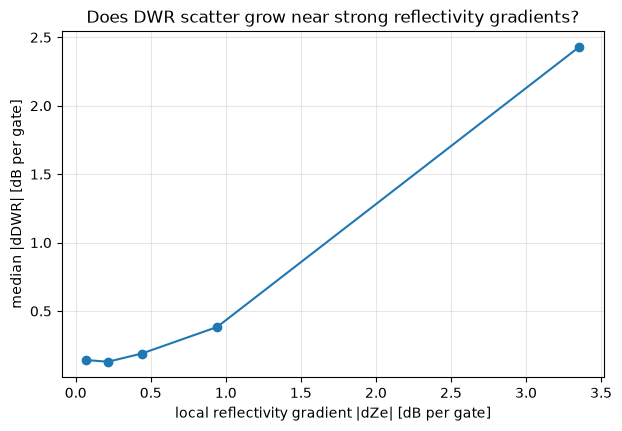

In [18]:
ze_W_masked = ds_retrieval["Ze_W"].where(mask_retrieval).values

# Local reflectivity gradient magnitude, gate to gate
reflectivity_gradient = np.abs(ze_W_masked[:, 1:] - ze_W_masked[:, :-1])
# Local DWR scatter, same gate pairs
dwr_local_scatter = np.abs(dwr_masked_values[:, 1:] - dwr_masked_values[:, :-1])

valid_pairs = np.isfinite(reflectivity_gradient) & np.isfinite(dwr_local_scatter)
gradient_valid = reflectivity_gradient[valid_pairs]
scatter_valid = dwr_local_scatter[valid_pairs]

# Bin by reflectivity gradient and take the median DWR scatter in each bin.
gradient_bin_edges = np.percentile(gradient_valid, [0, 20, 40, 60, 80, 100])
print("median |dDWR| as a function of local |dZe|:")
print(f"{'|dZe| bin (dB)':<22}{'n':>8}{'median |dDWR| (dB)':>22}")

bin_centres = []
bin_medians = []
for i in range(len(gradient_bin_edges) - 1):
    low, high = gradient_bin_edges[i], gradient_bin_edges[i + 1]
    in_bin = (gradient_valid >= low) & (gradient_valid < high)
    if in_bin.sum() > 10:
        median_scatter = float(np.median(scatter_valid[in_bin]))
        print(f"{low:6.2f} - {high:6.2f}      {in_bin.sum():>8}{median_scatter:>22.3f}")
        bin_centres.append(0.5 * (low + high))
        bin_medians.append(median_scatter)

correlation_gradient_scatter = float(np.corrcoef(gradient_valid, scatter_valid)[0, 1])
print(f"\ncorrelation(|dZe|, |dDWR|) = {correlation_gradient_scatter:+.3f}")
print("Clearly positive -> consistent with range-sidelobe contamination.")
print("Near zero        -> sidelobes are probably not the dominant error.")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(bin_centres, bin_medians, "o-")
ax.set_xlabel("local reflectivity gradient |dZe| [dB per gate]")
ax.set_ylabel("median |dDWR| [dB per gate]")
ax.set_title("Does DWR scatter grow near strong reflectivity gradients?")
ax.grid(alpha=0.3)
plt.show()


 ---

 ## Step 10 — Save

In [19]:
ds_uncertainty = xr.Dataset(
    {
        "LWC_uncertainty": lwc_uncertainty_final,
        "M_effective": m_effective,
        "delta_kappa": delta_kappa_field,
        "n_used":          n_used,                    # per profile
        "window_span_m":   window_span_km * 1000.0,   # per profile
    },
    attrs={
        "description": "Per-gate LWC retrieval uncertainty, Zhu et al. (2019) Eq. 5-8",
        "sigma_dwr_measured_db": sigma_dwr_measured_median,
        "sigma_dwr_theoretical_db": sigma_dwr_theoretical_median,
        "ratio_measured_to_theoretical": ratio_measured_to_theoretical,
        "gate_spacing_m": gate_spacing_m,
        "dwell_time_s": dwell_time_s,
        "assumed_prf_hz": prf_W_hz,
        "assumed_spectral_width_m_per_s": spectral_width_W_m_per_s,
        "assumed_snr_db": 10 * np.log10(snr_W_linear),
        "note_dh": "dh in Zhu Eq.5 is the WINDOW SPAN (N*gate spacing), not the "
                   "gate spacing as the paper text states. Verified against Hogan Eq.7.",
        "created_by": "06_error_estimation.ipynb",
    },
)



In [20]:
output_path = Path("../data/processed/lwc_uncertainty.nc")
output_path.parent.mkdir(parents=True, exist_ok=True)
ds_uncertainty.to_netcdf(output_path)

print(f"Saved -> {output_path}")
print(ds_uncertainty)

Saved -> ..\data\processed\lwc_uncertainty.nc
<xarray.Dataset> Size: 164MB
Dimensions:          (Time: 29682, range: 229)
Coordinates:
  * Time             (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.05295848...
  * range            (range) float64 2kB 223.6 238.5 ... 3.952e+03 3.986e+03
Data variables:
    LWC_uncertainty  (Time, range) float64 54MB nan nan nan nan ... nan nan nan
    M_effective      (Time, range) float64 54MB nan nan nan nan ... nan nan nan
    delta_kappa      (Time, range) float64 54MB 3.643 3.639 3.635 ... 3.692 3.69
    n_used           (Time) int64 237kB 0 0 0 0 0 0 0 0 0 ... 3 3 3 3 3 0 0 0 0
    window_span_m    (Time) float64 237kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Attributes:
    description:                     Per-gate LWC retrieval uncertainty, Zhu ...
    sigma_dwr_measured_db:           0.4316020877038294
    sigma_dwr_theoretical_db:        0.019660279522481366
    ratio_measured_to_theoretical:   21.952998542584098
    gate_spacing_m:          

In [21]:
print(lwc_uncertainty_final.attrs)
print(m_effective.attrs)
print(delta_kappa_field.attrs)

{'units': 'g m-3', 'long_name': '1-sigma LWC retrieval uncertainty', 'method': 'Zhu et al. (2019) Eq. 5-8, sigma_DWR measured from data', 'note': 'dh = N * gate spacing (window span), NOT the gate spacing', 'sigma_dwr_db': 0.4316020877038294}
{'long_name': 'Effective sample size per gate (Zhu et al. 2019 Eq. 8)', 'note': 'empirical autocorrelation of the per-window LWC estimates; clipped to [1, M]. Divide sigma_single by sqrt(M_eff) for the final averaged uncertainty (Eq. 7).'}
{'units': 'dB km-1 (g m-3)-1', 'model': 'Liebe et al. 1989 double-Debye'}


 ---

 ## Summary for the thesis



 | quantity | value |

 |---|---|

 | measured sigma(DWR) | see Step 2 |

 | theoretical sigma(DWR) (Zhu Eq. 6) | see Step 3 |

 | ratio | see Step 4 |

 | median sigma(LWC) | see Step 6 |

 | fraction LWC < 0 | see Step 7 |

 | fraction significantly < 0 | see Step 7 |



 **Assumptions to state explicitly:**



 1. PRF = 6250 Hz (from Hogan's worked example; an FMCW radar has no true PRF)

 2. Spectral width = 0.3 m/s (Hogan's stratocumulus value)

 3. SNR = 20 dB, or per-gate from `Ze - SL` if the sensitivity limits are used

 4. Range gates are statistically independent

 5. Errors are Gaussian

 6. Zhu Eq. (6) assumes a pulsed radar with no spectral processing; ours is

    FMCW, so the theoretical value is a lower bound rather than an estimate

## Uncertainty due to cloud thickness

In [22]:
import numpy as np

# ---- inputs -------------------------------------------------------------
dwr   = dwr_filtered                      # (Time, range), 30 s averaged
m     = mask_retrieval                              # (Time, range) bool
lwc   = lwc_zhu.values if hasattr(lwc_zhu, "values") else lwc_zhu
r_m   = r                                 # range coordinate, metres

DKAPPA   = 3.4          # dB/km/(g/m3)  -- replace with your field median
EDGE_PAD = 1            # what zhu.py currently uses
N_DEF    = 9
SPLIT    = 9            # thickness threshold, in gates


def sigma_dwr_split(dwr, m, rows):
    """sigma_DWR for a subset of profiles, split into edge and interior pairs.
    Per-profile linear trend removed so a constant true gradient doesn't count."""
    edge, interior = [], []
    kk = np.arange(dwr.shape[1], dtype=float)
    for t in np.flatnonzero(rows):
        idx = np.flatnonzero(m[t] & np.isfinite(dwr[t]))
        if idx.size < 4:
            continue
        x = dwr[t].astype(float).copy()
        x[~m[t]] = np.nan
        g = np.isfinite(x)
        x[g] -= np.polyval(np.polyfit(kk[g], x[g], 1), kk[g])
        lo, hi = idx[0], idx[-1]
        for k in range(lo, hi):
            d = x[k + 1] - x[k]
            if np.isfinite(d):
                (edge if (k == lo or k == hi - 1) else interior).append(d)
    e, i = np.array(edge), np.array(interior)
    out = {}
    for name, a in (("edge", e), ("interior", i), ("all", np.concatenate([e, i]))):
        out[name] = (a.std(ddof=1) / np.sqrt(2), a.size) if a.size > 30 else (np.nan, a.size)
    return out


def sigma_lwc_ols(sigma_dwr, N, dr_km, dkappa):
    """Exact OLS slope error for an N-gate fit. Best case: quadratic evaluated
    at the window centre. Away from centre it is up to 3.7x worse."""
    if N < 2:
        return np.nan
    return sigma_dwr / (dr_km * np.sqrt(N * (N**2 - 1) / 12.0)) * 0.5 / dkappa


# ---- classify profiles --------------------------------------------------
thick_gates = np.array([m[t].sum() for t in range(m.shape[0])])
has_cloud   = thick_gates >= 3

groups = {
    f"thin  (< {SPLIT} gates)":  has_cloud & (thick_gates <  SPLIT),
    f"thick (>= {SPLIT} gates)": has_cloud & (thick_gates >= SPLIT),
}

print(f"profiles with cloud: {has_cloud.sum()}")
print(f"thickness: median {np.median(thick_gates[has_cloud]):.0f}, "
      f"p90 {np.percentile(thick_gates[has_cloud], 90):.0f}, "
      f"max {thick_gates.max()} gates\n")

for label, rows in groups.items():
    if rows.sum() < 20:
        print(f"{label}: only {rows.sum()} profiles -- skipping\n")
        continue

    T   = thick_gates[rows]
    Neff = np.clip(np.minimum(N_DEF, T - 2 * EDGE_PAD), 0, None)
    dr_km = float(np.median(np.diff(r_m))) / 1000.0

    s = sigma_dwr_split(dwr, m, rows)
    v = lwc[rows][m[rows] & np.isfinite(lwc[rows])]

    N_med = int(np.median(Neff))
    pred  = sigma_lwc_ols(s["all"][0], N_med, dr_km, DKAPPA)

    print(f"--- {label} ---")
    print(f"  profiles              {rows.sum()}")
    print(f"  thickness  median     {np.median(T):.0f} gates")
    print(f"  N actually used       median {N_med}, min {Neff.min():.0f}, "
          f"max {Neff.max():.0f}")
    print(f"  sigma_DWR  edge       {s['edge'][0]:.3f} dB  (n={s['edge'][1]})")
    print(f"             interior   {s['interior'][0]:.3f} dB  (n={s['interior'][1]})")
    print(f"             pooled     {s['all'][0]:.3f} dB")
    print(f"  sigma_LWC  predicted  {pred:.3f} g/m3   (OLS, N={N_med}, best case)")
    print(f"  LWC        std        {v.std():.3f} g/m3")
    print(f"             median     {np.median(v):+.3f}")
    print(f"             mean       {v.mean():+.3f}")
    print(f"             |LWC| > 2  {(np.abs(v) > 2).mean():.1%}")
    print(f"             LWC  < 0   {(v < 0).mean():.1%}")
    print(f"  measured/predicted    x{v.std()/pred:.2f}\n")

profiles with cloud: 18964
thickness: median 11, p90 18, max 21 gates

--- thin  (< 9 gates) ---
  profiles              7829
  thickness  median     5 gates
  N actually used       median 3, min 1, max 6
  sigma_DWR  edge       2.110 dB  (n=11479)
             interior   0.518 dB  (n=14301)
             pooled     1.629 dB
  sigma_LWC  predicted  12.550 g/m3   (OLS, N=3, best case)
  LWC        std        2.032 g/m3
             median     +0.952
             mean       +0.499
             |LWC| > 2  41.5%
             LWC  < 0   34.0%
  measured/predicted    x0.16

--- thick (>= 9 gates) ---
  profiles              11135
  thickness  median     13 gates
  N actually used       median 9, min 7, max 9
  sigma_DWR  edge       2.113 dB  (n=22267)
             interior   0.351 dB  (n=123225)
             pooled     1.103 dB
  sigma_LWC  predicted  1.551 g/m3   (OLS, N=9, best case)
  LWC        std        1.230 g/m3
             median     +0.848
             mean       +0.780
           

In [23]:
import numpy as np
import matplotlib.pyplot as plt

dwr = dwr_filtered              # (Time, range), 30 s averaged
m   = mask_retrieval                      # (Time, range) bool
r   = ds_retrieval["range"].values.astype(float)


def sigma_dwr(rows):
    """sigma_DWR from adjacent-gate differences, per-profile linear trend removed
    so a constant true gradient is not counted as noise."""
    k, out = np.arange(dwr.shape[1], dtype=float), []
    for t in np.flatnonzero(rows):
        x = dwr[t].astype(float).copy()
        x[~m[t]] = np.nan
        g = np.isfinite(x)
        if g.sum() < 4:
            continue
        x[g] -= np.polyval(np.polyfit(k[g], x[g], 1), k[g])
        d = np.diff(x)
        out.append(d[np.isfinite(d)])
    if not out:
        return np.nan, 0
    d = np.concatenate(out)
    return (d.std(ddof=1) / np.sqrt(2), d.size) if d.size > 30 else (np.nan, d.size)


# cloud geometry per profile
n_gates = np.zeros(m.shape[0], int)
thick_m = np.full(m.shape[0], np.nan)
for t in range(m.shape[0]):
    idx = np.flatnonzero(m[t])
    if idx.size >= 3:
        n_gates[t] = idx.size
        thick_m[t] = r[idx[-1]] - r[idx[0]]

cloudy = n_gates >= 3
print(f"{cloudy.sum()} cloudy profiles | thickness median "
      f"{np.nanmedian(thick_m[cloudy]):.0f} m "
      f"({np.median(n_gates[cloudy]):.0f} gates)\n")

# the split you asked for
for lab, rows in [("<= 200 m", cloudy & (thick_m <= 200)),
                  ("> 200 m",  cloudy & (thick_m >  200))]:
    s, n = sigma_dwr(rows)
    print(f"{lab:9s}  sigma_DWR = {s:.3f} dB   "
          f"({rows.sum()} profiles, {n} pairs)")

18964 cloudy profiles | thickness median 149 m (11 gates)

<= 200 m   sigma_DWR = 1.320 dB   (14607 profiles, 100465 pairs)
> 200 m    sigma_DWR = 0.996 dB   (4357 profiles, 70807 pairs)


   0- 100 m: sigma_DWR 1.655 dB | std(LWC) 2.156 | LWC<0 38% | n=7536
 100- 150 m: sigma_DWR 1.234 dB | std(LWC) 1.140 | LWC<0 13% | n=2682
 150- 200 m: sigma_DWR 1.180 dB | std(LWC) 1.146 | LWC<0 20% | n=4389
 200- 250 m: sigma_DWR 0.964 dB | std(LWC) 1.235 | LWC<0 30% | n=2114
 250- 300 m: sigma_DWR 1.020 dB | std(LWC) 1.286 | LWC<0 32% | n=2243


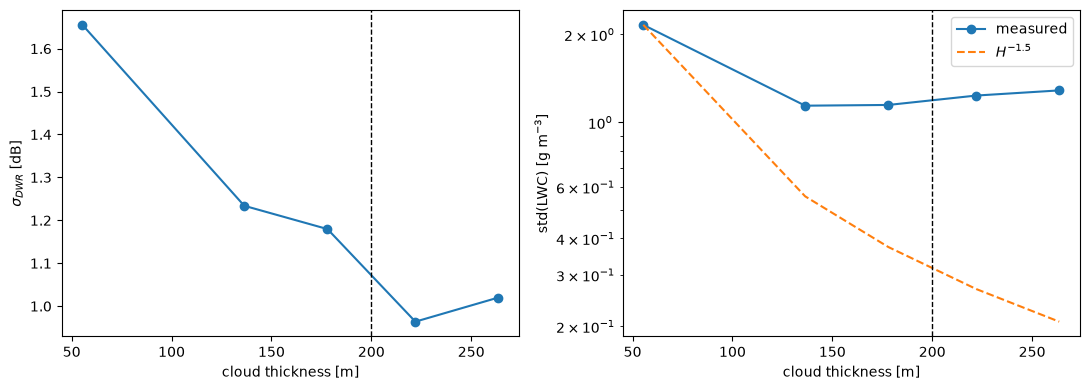

In [24]:
edges = np.array([0, 100, 150, 200, 250, 300, 400, 500, 600, 700, 800, 1000])
ctr, sig, lstd, lneg = [], [], [], []

for i in range(len(edges) - 1):
    rows = cloudy & (thick_m >= edges[i]) & (thick_m < edges[i+1])
    if rows.sum() < 30:
        continue
    s, _ = sigma_dwr(rows)
    v = lwc_zhu.values[rows][m[rows] & np.isfinite(lwc_zhu.values[rows])]
    ctr.append(np.nanmean(thick_m[rows])); sig.append(s)
    lstd.append(v.std()); lneg.append((v < 0).mean())
    print(f"{edges[i]:4.0f}-{edges[i+1]:4.0f} m: sigma_DWR {s:.3f} dB | "
          f"std(LWC) {v.std():.3f} | LWC<0 {(v<0).mean():.0%} | n={rows.sum()}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ctr, sig, "o-"); ax[0].axvline(200, color="k", ls="--", lw=1)
ax[0].set_xlabel("cloud thickness [m]"); ax[0].set_ylabel(r"$\sigma_{DWR}$ [dB]")
ax[1].plot(ctr, lstd, "o-", label="measured")
ax[1].plot(ctr, lstd[0] * (np.array(ctr)/ctr[0])**-1.5, "--", label=r"$H^{-1.5}$")
ax[1].axvline(200, color="k", ls="--", lw=1); ax[1].set_yscale("log")
ax[1].set_xlabel("cloud thickness [m]"); ax[1].set_ylabel("std(LWC) [g m$^{-3}$]")
ax[1].legend()
plt.tight_layout(); plt.show()

In [25]:
lwc = lwc_zhu.values
for lab, rows in [("< 9 gates",  cloudy & (n_gates <  9)),
                  (">= 9 gates", cloudy & (n_gates >= 9))]:
    v = lwc[rows][m[rows] & np.isfinite(lwc[rows])]
    if v.size < 50:
        print(f"{lab}: only {v.size} values"); continue
    print(f"{lab:11s} n={v.size:6d}  std={v.std():.3f}  "
          f"median={np.median(v):+.3f}  mean={v.mean():+.3f}  "
          f"|LWC|>2: {(np.abs(v)>2).mean():5.1%}  LWC<0: {(v<0).mean():5.1%}")

< 9 gates   n=  1152  std=2.032  median=+0.952  mean=+0.499  |LWC|>2: 41.5%  LWC<0: 34.0%
>= 9 gates  n=124759  std=1.230  median=+0.848  mean=+0.780  |LWC|>2: 16.3%  LWC<0: 24.6%


## Uncertainty with and without edge pads

In [26]:
import numpy as np, xarray as xr

TR      = lambda a: a.transpose("Time", "range")
target  = TR(dwr_filtered)
to_grid = lambda a: TR(a).reindex_like(target)

mask45 = to_grid(ds_retrieval["common_mask"]).fillna(False).astype(bool)
DKAPPA = to_grid(ds_retrieval["kappa_W"] - ds_retrieval["kappa_Ka"])
DR_KM  = float(np.median(np.diff(target["range"].values))) / 1000.0

# sigma_DWR measured from adjacent-gate differences, INTERIOR pairs only.
# Cloud-boundary pairs give 0.426 dB; that excess is treated separately.
SIG_DWR = 0.223

# Quadratic-fit penalty, measured by Monte Carlo of the actual algorithm on
# pure noise. zhu.py assigns dDWR/dh to EVERY gate in the window, but the
# derivative of a quadratic is only well determined near the window centre,
# so the true error exceeds the OLS lever-arm formula by this factor.
_PEN_N = {3: 2.99, 4: 2.71, 5: 2.59, 6: 2.55, 7: 2.52, 8: 2.51, 9: 2.47}
_PEN_T = np.array([[11, 2.39], [13, 2.31], [16, 2.19], [20, 2.04], [28, 1.85]])

def quad_penalty(N, thickness):
    """N < 9 -> one window. N = 9 -> several overlapping windows average down."""
    N = int(N)
    if N < 9:
        return _PEN_N.get(N, 2.5)
    return float(np.interp(thickness, _PEN_T[:, 0], _PEN_T[:, 1]))

print(f"gate spacing   {DR_KM*1000:.1f} m")
print(f"median dkappa  {float(DKAPPA.where(mask45).median()):.2f} dB/km/(g/m3)")
print(f"sigma_DWR used {SIG_DWR:.3f} dB (interior)")

gate spacing   13.5 m
median dkappa  3.59 dB/km/(g/m3)
sigma_DWR used 0.223 dB (interior)


In [27]:
r  = target["range"].values
Tg = np.array([np.flatnonzero(mm).size if mm.any() else 0
               for mm in mask45.values])

for pad in (0, 1):
    d = xr.open_dataset(f"../data/processed/retrieval_output_zhu_pad{pad}.nc")
    N = d["N_used"].values

    pen = np.array([quad_penalty(n, t) if n >= 3 else np.nan
                    for n, t in zip(N, Tg)])
    lever = DR_KM * np.sqrt(np.where(N >= 2, N * (N**2 - 1) / 12.0, np.nan))

    sig = xr.DataArray(pen / lever, dims=["Time"],
                       coords={"Time": d["Time"]})
    sig = (sig * SIG_DWR * 0.5 / DKAPPA).where(mask45)
    sig.name = "LWC_uncertainty"
    sig.attrs = {"units": "g m-3",
                 "long_name": "1-sigma LWC uncertainty",
                 "sigma_dwr_db": SIG_DWR, "edge_pad": pad,
                 "note": "OLS lever arm x MC quadratic penalty; per-profile N"}

    lwc = d["lwc_guarded"].where(mask45)
    v, s = lwc.values.ravel(), sig.values.ravel()
    ok = np.isfinite(v) & np.isfinite(s)
    v, s = v[ok], s[ok]
    neg = v < 0

    print(f"--- edge_pad={pad} ---")
    print(f"  median N used          {np.median(N[N > 0]):.0f} gates")
    print(f"  median sigma_LWC       {np.median(s):.3f} g/m3")
    print(f"  std of LWC             {v.std():.3f} g/m3")
    print(f"  fraction LWC < 0       {neg.mean():.1%}")
    print(f"  significantly < 0      {((v + s) < 0).mean():.1%}")
    print(f"  negatives within 1sig  {((v[neg] + s[neg]) >= 0).mean():.1%}"
          f"   (Socuellamos: >95%)\n")

    xr.Dataset({"LWC_uncertainty": sig,
                "N_used": d["N_used"]}).to_netcdf(
        f"../data/processed/lwc_uncertainty_pad{pad}.nc")

--- edge_pad=0 ---
  median N used          9 gates
  median sigma_LWC       nan g/m3
  std of LWC             nan g/m3
  fraction LWC < 0       nan%
  significantly < 0      nan%
  negatives within 1sig  nan%   (Socuellamos: >95%)

--- edge_pad=1 ---
  median N used          9 gates
  median sigma_LWC       nan g/m3
  std of LWC             nan g/m3
  fraction LWC < 0       nan%
  significantly < 0      nan%
  negatives within 1sig  nan%   (Socuellamos: >95%)



c:\Users\geron\miniforge3\envs\radar_lwc\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\geron\miniforge3\envs\radar_lwc\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\geron\miniforge3\envs\radar_lwc\Lib\site-packages\numpy\_core\_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\geron\miniforge3\envs\radar_lwc\Lib\site-packages\numpy\_core\_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\geron\miniforge3\envs\radar_lwc\Lib\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\geron\AppData\Local\Temp\ipykernel_45580\3173831125.

In [28]:
d = xr.open_dataset("../data/processed/retrieval_output_zhu_pad1.nc")
N = d["N_used"].values
L = d["lwc_guarded"].where(mask45).values
dk_med = float(DKAPPA.where(mask45).median())

print("predicted vs observed, by window size")
print(f"{'N':>4}{'profiles':>10}{'penalty':>9}{'predicted':>11}"
      f"{'observed':>10}{'ratio':>8}")
for n in range(3, 10):
    rows = N == n
    if rows.sum() < 20:
        continue
    v = L[rows]; v = v[np.isfinite(v)]
    if v.size < 50:
        continue
    pen  = quad_penalty(n, np.median(Tg[rows]))
    pred = pen * SIG_DWR / (DR_KM * np.sqrt(n*(n**2-1)/12.)) * 0.5 / dk_med
    print(f"{n:>4}{rows.sum():>10}{pen:>9.2f}{pred:>11.3f}"
          f"{v.std():>10.3f}{v.std()/pred:>8.2f}")

print("\nN=9 split by cloud thickness (tests the cloud-boundary hypothesis)")
print(f"{'T':>9}{'profiles':>10}{'predicted':>11}{'observed':>10}{'ratio':>8}")
for lo, hi in [(11, 14), (14, 18), (18, 24), (24, 99)]:
    sel = (N == 9) & (Tg >= lo) & (Tg < hi)
    if sel.sum() < 20:
        continue
    v = L[sel]; v = v[np.isfinite(v)]
    pred = (quad_penalty(9, np.median(Tg[sel])) * SIG_DWR
            / (DR_KM * np.sqrt(9*80/12.)) * 0.5 / dk_med)
    print(f"{lo:>5}-{hi:<3}{sel.sum():>10}{pred:>11.3f}"
          f"{v.std():>10.3f}{v.std()/pred:>8.2f}")

predicted vs observed, by window size
   N  profiles  penalty  predicted  observed   ratio


IndexError: boolean index did not match indexed array along axis 0; size of axis is 0 but size of corresponding boolean axis is 14915

## Testing effect of different Guarded retrieval thresholds

In [29]:
import numpy as np, xarray as xr

from radar_lwc.retrieval.zhu import retrieve_lwc_zhu

TR      = lambda a: a.transpose("Time", "range")
target  = TR(dwr_filtered)
to_grid = lambda a: TR(a).reindex_like(target)
mask45  = to_grid(ds_retrieval["common_mask"]).fillna(False).astype(bool)

DKAPPA = to_grid(ds_retrieval["kappa_W"] - ds_retrieval["kappa_Ka"])
DALPHA = to_grid(ds_retrieval["alpha_W"] - ds_retrieval["alpha_Ka"])
dk = float(DKAPPA.where(mask45).median())
da = float(DALPHA.where(mask45).median())
dr = float(np.median(np.diff(target["range"].values)))

BASE_DDWR, BASE_STD = 100.0, 10.0
SCALES = [1.0, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1, 0.05]

print(f"dkappa {dk:.2f} | dalpha {da:.2f} | gate {dr:.1f} m")
print(f"{'scale':>7}{'ddwr':>8}{'wstd':>7}   LWC window accepted")
for s in SCALES:
    G = BASE_DDWR * s
    print(f"{s:>7.4f}{G:>8.1f}{BASE_STD*s:>7.2f}   "
          f"{(-0.5*G-da)/dk:+7.2f} .. {(0.5*G-da)/dk:+6.2f}  "
          f"(centre {-da/dk:+.2f})")

sweep = {}
for s in SCALES:
    lwc, ddwr, meff, nwin, nused = retrieve_lwc_zhu(
        dwr=target,
        kappa_w=to_grid(ds_retrieval["kappa_W"]),
        kappa_ka=to_grid(ds_retrieval["kappa_Ka"]),
        alpha_w=to_grid(ds_retrieval["alpha_W"]),
        alpha_ka=to_grid(ds_retrieval["alpha_Ka"]),
        cloud_mask=mask45,
        N_default=9, min_cloud_gates=3,
        max_ddwr_dh=BASE_DDWR * s,
        max_window_std=BASE_STD * s,
        edge_pad=0,
    )
    sweep[s] = xr.Dataset({"lwc": lwc, "dDWR_dh": ddwr, "n_windows": nwin,
                           "N_used": nused},
                          attrs={"max_ddwr_dh": BASE_DDWR*s,
                                 "max_window_std": BASE_STD*s})
    print(f"  scale {s:.4f}: {int(np.isfinite(lwc.values).sum())} gates")

dkappa 3.59 | dalpha 0.24 | gate 13.5 m
  scale    ddwr   wstd   LWC window accepted
 1.0000   100.0  10.00    -13.99 .. +13.85  (centre -0.07)
 0.6000    60.0   6.00     -8.42 ..  +8.29  (centre -0.07)
 0.5000    50.0   5.00     -7.03 ..  +6.89  (centre -0.07)
 0.4000    40.0   4.00     -5.64 ..  +5.50  (centre -0.07)
 0.3000    30.0   3.00     -4.24 ..  +4.11  (centre -0.07)
 0.2000    20.0   2.00     -2.85 ..  +2.72  (centre -0.07)
 0.1000    10.0   1.00     -1.46 ..  +1.32  (centre -0.07)
 0.0500     5.0   0.50     -0.76 ..  +0.63  (centre -0.07)
  scale 1.0000: 157559 gates
  scale 0.6000: 150217 gates
  scale 0.5000: 147902 gates
  scale 0.4000: 144244 gates
  scale 0.3000: 134888 gates
  scale 0.2000: 108782 gates
  scale 0.1000: 51387 gates
  scale 0.0500: 15960 gates


  scale   gates  keep%  median    mean    std    <0  |L|>2 |  LWPbias%  LWPrmse  corr
 1.0000  157559  100.0   0.784   0.310  2.733   32%  28.3% |      -8.2    131.7  0.22
 0.6000  150217   95.3   0.888   0.641  1.896   29%  25.3% |      66.3    113.1  0.25
 0.5000  147902   93.9   0.909   0.717  1.722   27%  24.5% |      81.8    113.4  0.23
 0.4000  144244   91.5   0.916   0.775  1.532   26%  22.8% |      92.9    114.7  0.19
 0.3000  134888   85.6   0.875   0.767  1.287   25%  17.9% |      90.0    110.9  0.13
 0.2000  108782   69.0   0.767   0.655  0.971   23%   7.5% |      57.1     98.4  0.07
 0.1000   51387   32.6   0.427   0.334  0.589   27%   0.0% |     -23.2     72.8  0.10
 0.0500   15960   10.1   0.131   0.085  0.324   37%   0.0% |     -80.8     73.5  0.09


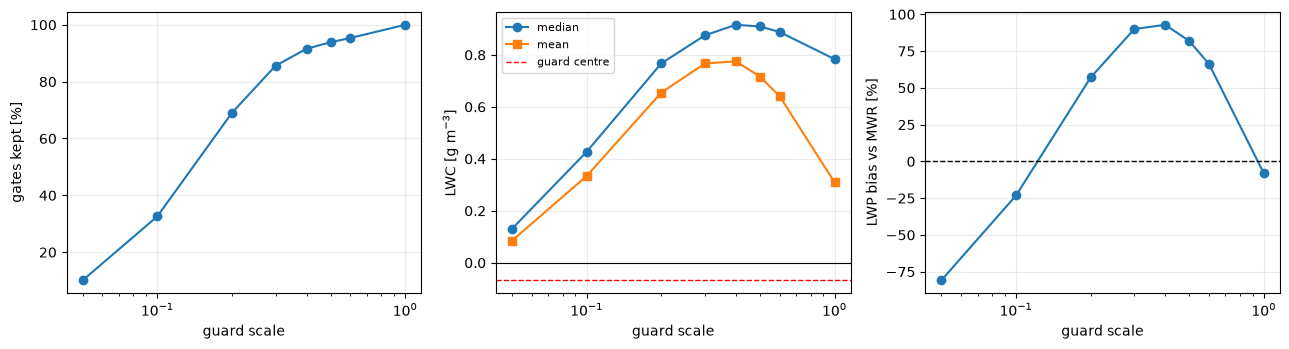

In [30]:
import matplotlib.pyplot as plt

m       = mask45.values
lwp_mwr = ds_retrieval["LWP"].values
base_n  = int(np.isfinite(sweep[SCALES[0]]["lwc"].values).sum())
rows    = []

for s in SCALES:
    L = sweep[s]["lwc"].where(mask45).values
    v = L[np.isfinite(L)]

    lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0), axis=1) * dr
    lwp_r[~np.isfinite(L).any(axis=1)] = np.nan

    ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 20)
    relbias = np.median(100*(lwp_r[ok]-lwp_mwr[ok])/lwp_mwr[ok]) if ok.sum() > 30 else np.nan
    rmse    = np.sqrt(np.mean((lwp_r[ok]-lwp_mwr[ok])**2)) if ok.sum() > 30 else np.nan
    corr    = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0,1] if ok.sum() > 30 else np.nan

    rows.append(dict(s=s, gates=v.size, keep=100*v.size/base_n,
                     med=np.median(v), mean=v.mean(), std=v.std(),
                     neg=(v<0).mean(), big=(np.abs(v)>2).mean(),
                     bias=relbias, rmse=rmse, corr=corr, n=int(ok.sum())))

print(f"{'scale':>7}{'gates':>8}{'keep%':>7}{'median':>8}{'mean':>8}{'std':>7}"
      f"{'<0':>6}{'|L|>2':>7} | {'LWPbias%':>9}{'LWPrmse':>9}{'corr':>6}")
for x in rows:
    print(f"{x['s']:>7.4f}{x['gates']:>8}{x['keep']:>7.1f}{x['med']:>8.3f}"
          f"{x['mean']:>8.3f}{x['std']:>7.3f}{x['neg']:>6.0%}{x['big']:>7.1%}"
          f" | {x['bias']:>9.1f}{x['rmse']:>9.1f}{x['corr']:>6.2f}")

sc = [x['s'] for x in rows]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].semilogx(sc, [x['keep'] for x in rows], "o-")
ax[0].set_ylabel("gates kept [%]"); ax[0].set_xlabel("guard scale")
ax[1].semilogx(sc, [x['med'] for x in rows], "o-", label="median")
ax[1].semilogx(sc, [x['mean'] for x in rows], "s-", label="mean")
ax[1].axhline(-da/dk, color="r", ls="--", lw=1, label="guard centre")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_ylabel("LWC [g m$^{-3}$]"); ax[1].set_xlabel("guard scale"); ax[1].legend(fontsize=8)
ax[2].semilogx(sc, [x['bias'] for x in rows], "o-")
ax[2].axhline(0, color="k", ls="--", lw=1)
ax[2].set_ylabel("LWP bias vs MWR [%]"); ax[2].set_xlabel("guard scale")
for a in ax: a.grid(alpha=0.25)
plt.tight_layout(); plt.show()

In [ ]:
import numpy as np, xarray as xr

TR      = lambda a: a.transpose("Time", "range")
target  = TR(dwr_filtered)
to_grid = lambda a: TR(a).reindex_like(target)
mask45  = to_grid(ds_retrieval["common_mask"]).fillna(False).astype(bool)

DKAPPA = to_grid(ds_retrieval["kappa_W"]  - ds_retrieval["kappa_Ka"])
DALPHA = to_grid(ds_retrieval["alpha_W"]  - ds_retrieval["alpha_Ka"])
dk = float(DKAPPA.where(mask45).median())
da = float(DALPHA.where(mask45).median())
dr = float(np.median(np.diff(target["range"].values)))

OFF_DDWR, OFF_STD = 1e6, 1e6          # "guard disabled"
DDWR_VALUES = [1e6, 100.0, 80.0, 70.0, 60.0, 50.0, 40.0, 30.0, 20.0, 10.0]
STD_VALUES  = [1e6,  10.0, 5.0, 2.0, 1.5, 1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2]

print(f"dkappa {dk:.2f} | dalpha {da:.2f} | gate {dr:.1f} m\n")
print("max_ddwr_dh -> LWC window it accepts:")
for G in DDWR_VALUES[1:]:
    print(f"  {G:7.2f} dB/km : {(-0.5*G-da)/dk:+7.2f} .. {(0.5*G-da)/dk:+6.2f}"
          f"   (centre {-da/dk:+.2f}, NOT zero)")

def run(ddwr, wstd):
    lwc, ddw, meff, nwin, nused = retrieve_lwc_zhu(
        dwr=target,
        kappa_w=to_grid(ds_retrieval["kappa_W"]),
        kappa_ka=to_grid(ds_retrieval["kappa_Ka"]),
        alpha_w=to_grid(ds_retrieval["alpha_W"]),
        alpha_ka=to_grid(ds_retrieval["alpha_Ka"]),
        cloud_mask=mask45,
        N_default=9, min_cloud_gates=3,
        max_ddwr_dh=ddwr, max_window_std=wstd, edge_pad=0)
    return xr.Dataset({"lwc": lwc, "dDWR_dh": ddw,
                       "n_windows": nwin, "N_used": nused})

sweep_ddwr = {}
print("\nsweeping max_ddwr_dh (max_window_std OFF):")
for G in DDWR_VALUES:
    sweep_ddwr[G] = run(G, OFF_STD)
    print(f"  {G:9.2f}: {int(np.isfinite(sweep_ddwr[G]['lwc'].values).sum())} gates")

sweep_std = {}
print("\nsweeping max_window_std (max_ddwr_dh OFF):")
for S in STD_VALUES:
    sweep_std[S] = run(OFF_DDWR, S)
    print(f"  {S:9.2f}: {int(np.isfinite(sweep_std[S]['lwc'].values).sum())} gates")

dkappa 3.59 | dalpha 0.24 | gate 13.5 m

max_ddwr_dh -> LWC window it accepts:
   100.00 dB/km :  -13.99 .. +13.85   (centre -0.07, NOT zero)
    80.00 dB/km :  -11.20 .. +11.07   (centre -0.07, NOT zero)
    70.00 dB/km :   -9.81 ..  +9.68   (centre -0.07, NOT zero)
    60.00 dB/km :   -8.42 ..  +8.29   (centre -0.07, NOT zero)
    50.00 dB/km :   -7.03 ..  +6.89   (centre -0.07, NOT zero)
    40.00 dB/km :   -5.64 ..  +5.50   (centre -0.07, NOT zero)
    30.00 dB/km :   -4.24 ..  +4.11   (centre -0.07, NOT zero)
    20.00 dB/km :   -2.85 ..  +2.72   (centre -0.07, NOT zero)
    10.00 dB/km :   -1.46 ..  +1.32   (centre -0.07, NOT zero)

sweeping max_ddwr_dh (max_window_std OFF):
  1000000.00: 193646 gates
     100.00: 157559 gates
      80.00: 154074 gates
      70.00: 152317 gates
      60.00: 150217 gates
      50.00: 147902 gates
      40.00: 144244 gates
      30.00: 134888 gates
      20.00: 108782 gates
      10.00: 51387 gates

sweeping max_window_std (max_ddwr_dh OFF):
  1000


=== max_ddwr_dh (dB/km) ===   [other guard disabled]
max_ddwr_dh    gates  keep%  median    mean    std    <0  |L|>2 |  LWPbias%  LWPrmse  corr      n
           off    86842  100.0   0.171  -0.011  1.327   38%   8.5% |     -14.5    152.3  0.41   7106
        100.00    86836  100.0   0.171  -0.010  1.325   38%   8.5% |     -14.5    152.3  0.41   7106
         80.00    86748   99.9   0.171  -0.006  1.297   38%   8.4% |     -14.1    149.5  0.41   7099
         70.00    86485   99.6   0.172   0.006  1.250   38%   8.2% |     -13.3    143.8  0.41   7075
         60.00    86052   99.1   0.173   0.022  1.183   38%   7.8% |     -12.4    136.8  0.41   7042
         50.00    85501   98.5   0.174   0.036  1.112   38%   7.4% |     -11.4    130.8  0.41   7011
         40.00    84624   97.4   0.176   0.054  1.036   37%   6.7% |      -8.9    124.8  0.41   6954
         30.00    82441   94.9   0.181   0.082  0.917   37%   5.3% |      -1.7    115.0  0.41   6768
         20.00    77379   89.1   0.191  

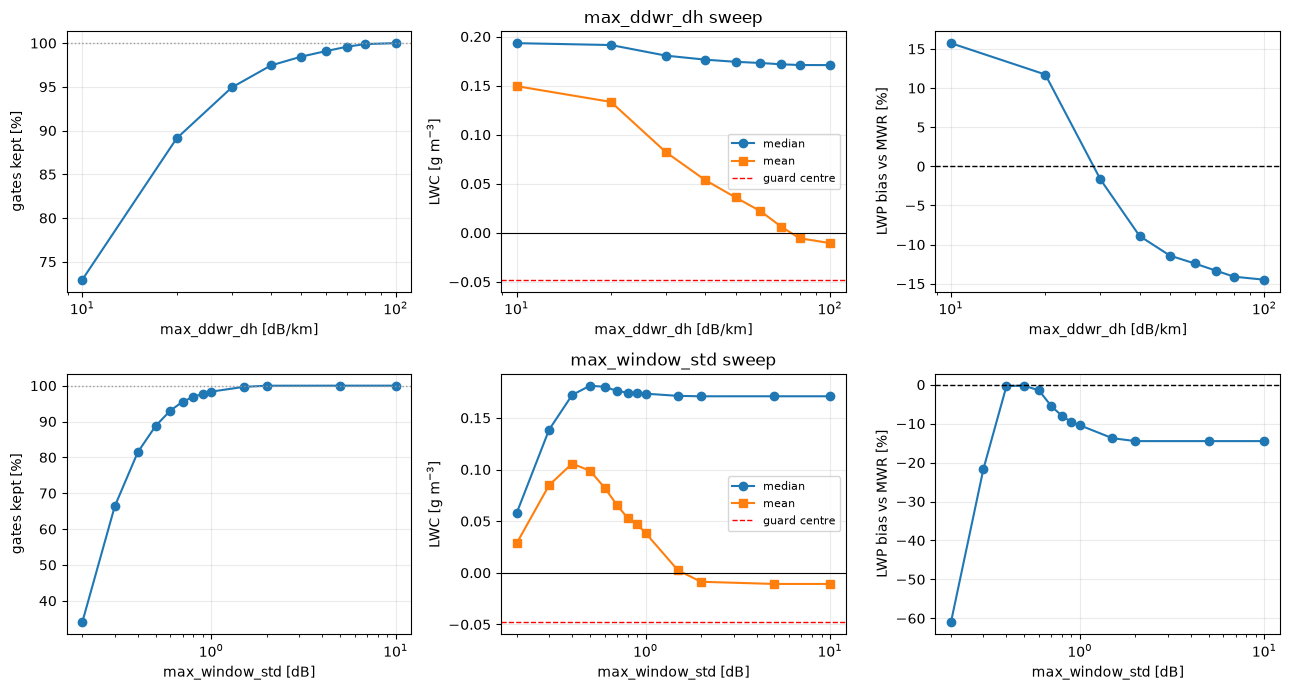

In [ ]:
import matplotlib.pyplot as plt

lwp_mwr = ds_retrieval["LWP"].values

def diagnose(sweep, values, name, unit):
    base_n = int(np.isfinite(sweep[values[0]]["lwc"].values).sum())
    rows = []
    for x in values:
        L = sweep[x]["lwc"].where(mask45).values
        v = L[np.isfinite(L)]

        lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0), axis=1) * dr
        lwp_r[~np.isfinite(L).any(axis=1)] = np.nan

        ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 20)
        if ok.sum() > 30:
            rel  = 100*(lwp_r[ok]-lwp_mwr[ok])/lwp_mwr[ok]
            bias, rmse = np.median(rel), np.sqrt(np.mean((lwp_r[ok]-lwp_mwr[ok])**2))
            corr = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1]
        else:
            bias = rmse = corr = np.nan

        rows.append(dict(x=x, gates=v.size, keep=100*v.size/base_n,
                         med=np.median(v), mean=v.mean(), std=v.std(),
                         neg=(v < 0).mean(), big=(np.abs(v) > 2).mean(),
                         bias=bias, rmse=rmse, corr=corr, n=int(ok.sum())))

    print(f"\n=== {name} ({unit}) ===   [other guard disabled]")
    print(f"{name:>11}{'gates':>9}{'keep%':>7}{'median':>8}{'mean':>8}{'std':>7}"
          f"{'<0':>6}{'|L|>2':>7} | {'LWPbias%':>9}{'LWPrmse':>9}{'corr':>6}{'n':>7}")
    for r_ in rows:
        lbl = "off" if r_['x'] > 1e5 else f"{r_['x']:.2f}"
        print(f"{lbl:>14}{r_['gates']:>9}{r_['keep']:>7.1f}{r_['med']:>8.3f}"
              f"{r_['mean']:>8.3f}{r_['std']:>7.3f}{r_['neg']:>6.0%}"
              f"{r_['big']:>7.1%} | {r_['bias']:>9.1f}{r_['rmse']:>9.1f}"
              f"{r_['corr']:>6.2f}{r_['n']:>7}")
    return rows


rows_g = diagnose(sweep_ddwr, DDWR_VALUES, "max_ddwr_dh", "dB/km")
rows_s = diagnose(sweep_std,  STD_VALUES,  "max_window_std", "dB")


def panel(axrow, rows, label):
    xs = [r_['x'] for r_ in rows[1:]]                 # drop the "off" point
    axrow[0].semilogx(xs, [r_['keep'] for r_ in rows[1:]], "o-")
    axrow[0].set_ylabel("gates kept [%]"); axrow[0].set_xlabel(label)
    axrow[1].semilogx(xs, [r_['med']  for r_ in rows[1:]], "o-", label="median")
    axrow[1].semilogx(xs, [r_['mean'] for r_ in rows[1:]], "s-", label="mean")
    axrow[1].axhline(-da/dk, color="r", ls="--", lw=1, label="guard centre")
    axrow[1].axhline(0, color="k", lw=0.8)
    axrow[1].set_ylabel("LWC [g m$^{-3}$]"); axrow[1].set_xlabel(label)
    axrow[1].legend(fontsize=8)
    axrow[2].semilogx(xs, [r_['bias'] for r_ in rows[1:]], "o-")
    axrow[2].axhline(0, color="k", ls="--", lw=1)
    axrow[2].set_ylabel("LWP bias vs MWR [%]"); axrow[2].set_xlabel(label)
    for a in axrow:
        a.grid(alpha=0.25)
        a.axhline(rows[0]['keep'] if a is axrow[0] else np.nan,
                  color="0.6", ls=":", lw=1)

fig, ax = plt.subplots(2, 3, figsize=(13, 7))
panel(ax[0], rows_g, "max_ddwr_dh [dB/km]")
panel(ax[1], rows_s, "max_window_std [dB]")
ax[0][1].set_title("max_ddwr_dh sweep")
ax[1][1].set_title("max_window_std sweep")
plt.tight_layout(); plt.show()

## LWP compared to ZHU Figure 5

In [ ]:
dz = float(dwr_filtered["range"].sel(range=slice(0, 4000)).diff("range").mean())
lwp_guarded_1500 = (lwc_zhu.where(ds_retrieval["common_mask"]& (ds_retrieval["range"] >= 1500)).fillna(0) * dz).sum(dim="range")
lwp_guarded_1500 = lwp_guarded_1500.where(ds_retrieval["common_mask"].any(dim="range"))
lwp_guarded_1500.attrs["units"] = "g m-2"

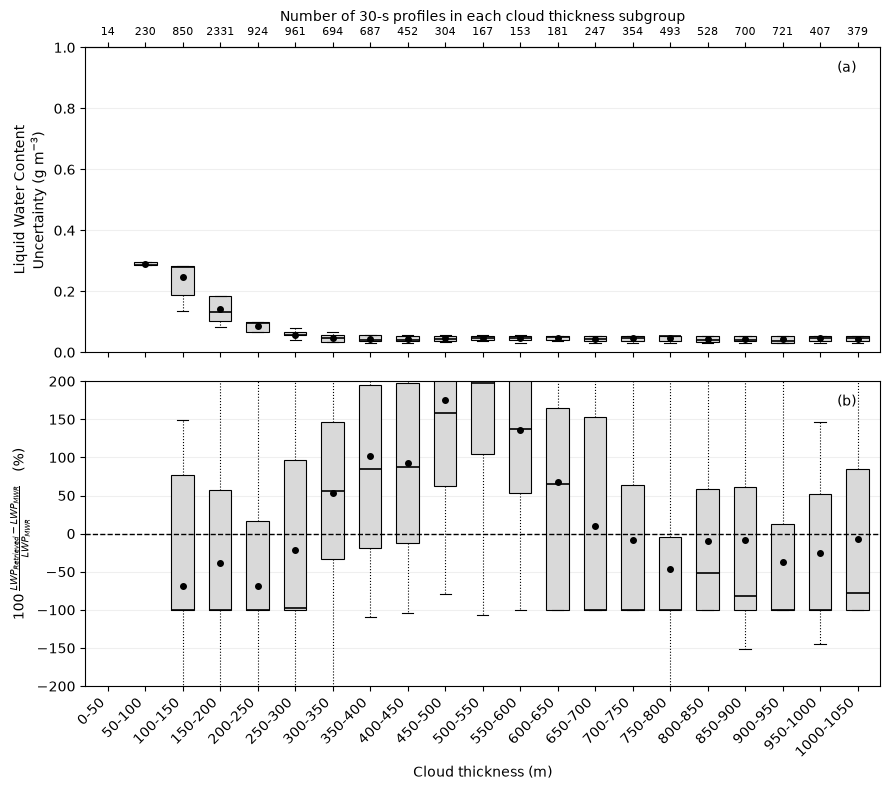

   thickness  profiles  med sigma  med rel %   n(b)
        0-50        14        nan        nan      0
      50-100       230      0.288     -100.0      2
     100-150       850      0.281     -100.0     63
     150-200      2331      0.132     -100.0   1299
     200-250       924      0.097     -100.0    799
     250-300       961      0.056      -97.8    904
     300-350       694      0.048       55.6    558
     350-400       687      0.040       84.6    499
     400-450       452      0.041       87.9    371
     450-500       304      0.045      157.9    290
     500-550       167      0.046      198.0    167
     550-600       153      0.047      136.7    152
     600-650       181      0.049       65.4    168
     650-700       247      0.045     -100.0    218
     700-750       354      0.045     -100.0    319
     750-800       493      0.054     -100.0    482
     800-850       528      0.039      -51.9    503
     850-900       700      0.039      -81.2    630
     900-950

In [ ]:
import numpy as np, matplotlib.pyplot as plt

# ---- inputs -------------------------------------------------------------
lwp_mwr   = ds_retrieval["LWP"].values
lwp_radar = lwp_guarded_1500.values
sig_lwc   = lwc_uncertainty_final          # (Time, range), from notebook 06
mask    = ds_retrieval["common_mask"].values
r         = target["range"].values
dr        = gate_spacing_m

LWP_MIN = 20.0        # g/m2; below this the ratio is dominated by MWR noise

# cloud geometric thickness per profile
thick = np.full(mask.shape[0], np.nan)
for t, mm in enumerate(mask):
    idx = np.flatnonzero(mm)
    if idx.size:
        thick[t] = r[idx[-1]] - r[idx[0]] + dr

# one uncertainty per profile
sig_prof = sig_lwc.where(mask).median("range").values

# relative LWP difference (%)
rel = np.full(lwp_mwr.shape, np.nan)
ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_radar) & (lwp_mwr > LWP_MIN)
rel[ok] = 100.0 * (lwp_radar[ok] - lwp_mwr[ok]) / lwp_mwr[ok]

# ---- bin by thickness ---------------------------------------------------
edges  = np.arange(0, 1100, 50)
labels = [f"{edges[i]}-{edges[i+1]}" for i in range(len(edges) - 1)]
box_a, box_b, n_prof = [], [], []
for i in range(len(edges) - 1):
    sel = (thick >= edges[i]) & (thick < edges[i + 1])
    a = sig_prof[sel]; box_a.append(a[np.isfinite(a)])
    b = rel[sel];      box_b.append(b[np.isfinite(b)])
    n_prof.append(int(sel.sum()))

# ---- plot ---------------------------------------------------------------
pos = np.arange(len(labels))
kw = dict(widths=0.6, patch_artist=True, showfliers=False, whis=(5, 95),
          showmeans=True, manage_ticks=False,
          boxprops=dict(facecolor="0.85", edgecolor="k", lw=0.8),
          medianprops=dict(color="k", lw=1.2),
          whiskerprops=dict(color="k", lw=0.8, linestyle=":"),
          capprops=dict(color="k", lw=0.8),
          meanprops=dict(marker="o", markerfacecolor="k",
                         markeredgecolor="k", markersize=4))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

ka = [i for i in pos if len(box_a[i]) >= 5]
ax1.boxplot([box_a[i] for i in ka], positions=pos[ka], **kw)
ax1.set_ylabel("Liquid Water Content\nUncertainty (g m$^{-3}$)")
ax1.set_ylim(0, max(1.0, np.nanpercentile(sig_prof, 98)))
ax1.text(0.97, 0.92, "(a)", transform=ax1.transAxes, ha="right")
ax1.grid(alpha=0.2, axis="y")

kb = [i for i in pos if len(box_b[i]) >= 5]
ax2.boxplot([box_b[i] for i in kb], positions=pos[kb], **kw)
ax2.axhline(0, color="k", ls="--", lw=1)
ax2.set_ylabel(r"$100\,\frac{LWP_{Retrieved}-LWP_{MWR}}{LWP_{MWR}}$   (%)")
ax2.set_ylim(-200, 200)
ax2.set_xlabel("Cloud thickness (m)")
ax2.text(0.97, 0.92, "(b)", transform=ax2.transAxes, ha="right")
ax2.grid(alpha=0.2, axis="y")

ax2.set_xticks(pos)
ax2.set_xticklabels(labels, rotation=45, ha="right")
ax2.set_xlim(-0.6, len(labels) - 0.4)

axt = ax1.secondary_xaxis("top")
axt.set_xticks(pos)
axt.set_xticklabels([str(n) for n in n_prof], fontsize=8)
axt.set_xlabel("Number of 30-s profiles in each cloud thickness subgroup")

plt.tight_layout()
plt.show()

# ---- the numbers behind the boxes ---------------------------------------
print(f"{'thickness':>12}{'profiles':>10}{'med sigma':>11}{'med rel %':>11}{'n(b)':>7}")
for i in pos:
    if n_prof[i] == 0:
        continue
    ma = np.median(box_a[i]) if len(box_a[i]) else np.nan
    mb = np.median(box_b[i]) if len(box_b[i]) else np.nan
    print(f"{labels[i]:>12}{n_prof[i]:>10}{ma:>11.3f}{mb:>11.1f}{len(box_b[i]):>7}")

In [ ]:
lwp_mwr = ds_retrieval["LWP"].values
r  = target["range"].values
dr = gate_spacing_m
mv = mask45.values

thick = np.full(mv.shape[0], np.nan)
ctop  = np.full(mv.shape[0], np.nan)
for t, mm in enumerate(mv):
    i = np.flatnonzero(mm)
    if i.size:
        thick[t] = r[i[-1]] - r[i[0]] + dr
        ctop[t]  = r[i[-1]]

print(f"{'thickness':>12}{'n':>7}{'LWP_MWR':>10}{'adiabatic':>11}{'ratio':>7}{'cldtop':>9}")
for lo in range(0, 1200, 50):
    sel = (thick >= lo) & (thick < lo+50) & np.isfinite(lwp_mwr)
    if sel.sum() < 20: continue
    H  = (lo + 25) / 1000.0
    ad = 0.5 * 2.0 * H**2 * 1000          # adiabatic LWP, g/m2
    med = np.median(lwp_mwr[sel])
    print(f"{lo:>5}-{lo+50:<6}{sel.sum():>7}{med:>10.1f}{ad:>11.1f}"
          f"{med/ad:>7.2f}{np.nanmedian(ctop[sel]):>9.0f}")

   thickness      n   LWP_MWR  adiabatic  ratio   cldtop
   50-100       230       6.9        5.6   1.22     1863
  100-150       850      10.3       15.6   0.66     2372
  150-200      2331      21.1       30.6   0.69     2372
  200-250       924      29.6       50.6   0.58     1620
  250-300       961      34.0       75.6   0.45     1593
  300-350       694      35.7      105.6   0.34     1647
  350-400       687      31.8      140.6   0.23     1674
  400-450       452      45.4      180.6   0.25     1701
  450-500       304      46.7      225.6   0.21     2372
  500-550       167      44.0      275.6   0.16     2372
  550-600       153      55.9      330.6   0.17     2410
  600-650       181      45.9      390.6   0.12     2448
  650-700       247      36.6      455.6   0.08     2561
  700-750       354      40.5      525.6   0.08     2598
  750-800       493      40.3      600.6   0.07     2636
  800-850       528      48.5      680.6   0.07     2674
  850-900       700      46.1  

In [ ]:
mv = mask45.values
r  = target["range"].values

n_layers, span, filled, thickest = [], [], [], []
for mm in mv:
    i = np.flatnonzero(mm)
    if i.size == 0:
        n_layers.append(0); span.append(np.nan)
        filled.append(np.nan); thickest.append(np.nan); continue
    breaks = np.flatnonzero(np.diff(i) > 1)
    runs = np.split(i, breaks + 1)
    n_layers.append(len(runs))
    span.append(r[i[-1]] - r[i[0]] + dr)
    filled.append(i.size / (i[-1] - i[0] + 1))
    L = max(runs, key=len)
    thickest.append(r[L[-1]] - r[L[0]] + dr)

n_layers = np.array(n_layers); span = np.array(span)
filled = np.array(filled); thickest = np.array(thickest)

ok = n_layers > 0
print(f"profiles with >1 layer: {(n_layers[ok] > 1).mean():.1%}")
print(f"{'span bin':>12}{'n':>7}{'layers':>8}{'filled':>8}{'span':>8}{'thickest':>10}")
for lo in range(0, 1200, 100):
    s = ok & (span >= lo) & (span < lo+100)
    if s.sum() < 20: continue
    print(f"{lo:>5}-{lo+100:<6}{s.sum():>7}{np.mean(n_layers[s]):>8.2f}"
          f"{np.mean(filled[s]):>8.2f}{np.median(span[s]):>8.0f}"
          f"{np.median(thickest[s]):>10.0f}")

profiles with >1 layer: 38.6%
    span bin      n  layers  filled    span  thickest
    0-100       244    1.00    1.00      92        92
  100-200      3181    1.00    1.00     151       151
  200-300      1885    1.00    1.00     251       251
  300-400      1381    1.09    0.99     348       339
  400-500       756    1.07    0.99     443       428
  500-600       320    1.22    0.98     547       527
  600-700       428    1.66    0.76     665       399
  700-800       847    1.98    0.62     753       267
  800-900      1228    2.07    0.62     859       332
  900-1000     1128    2.08    0.53     941       301
 1000-1100      630    2.01    0.45    1032       282
 1100-1200      225    2.00    0.27    1157       146
